In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import openpyxl

print("Libraries ready!")
print("Dataset found:", os.path.exists("online_retail_II.xlsx"))



Libraries ready!
Dataset found: True


In [2]:
sheets = pd.read_excel('online_retail_II.xlsx', sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

In [3]:
df = df.rename(columns={'Invoice':'InvoiceNo','Price':'UnitPrice','Customer ID':'CustomerID'})
print(df.shape)
df.info()
df.head(10)

(1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   InvoiceNo    1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   UnitPrice    1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


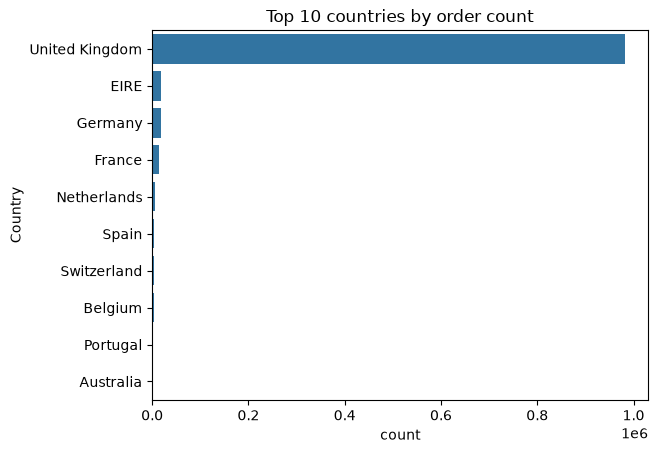

In [4]:
top = df['Country'].value_counts().head(10).index
sns.countplot(data=df[df['Country'].isin(top)], y='Country', order=top)
plt.title('Top 10 countries by order count')
plt.show()

In [5]:
df = df[df['Country'] == 'United Kingdom']
df = df.dropna(subset=['CustomerID'])
print('Rows after UK + null CustomerID filter:', len(df))

Rows after UK + null CustomerID filter: 741301


In [6]:
before = len(df)
df = df[df['Quantity'] > 0]
print('Rows dropped (Quantity <= 0):', before - len(df))

Rows dropped (Quantity <= 0): 16005


In [7]:
before = len(df)
df = df[df['UnitPrice'] > 0]
print('Rows dropped (UnitPrice <= 0):', before - len(df))

Rows dropped (UnitPrice <= 0): 46


In [8]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

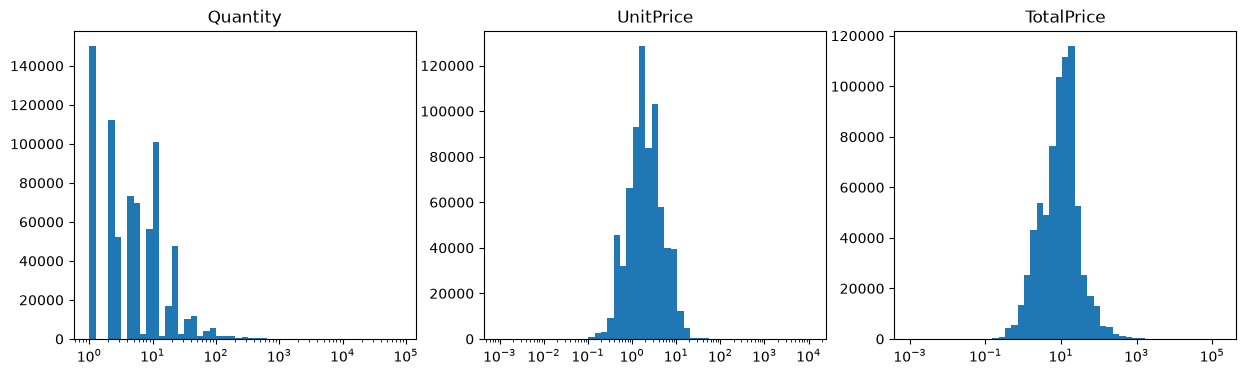

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, ['Quantity','UnitPrice','TotalPrice']):
    a.hist(df[c], bins=np.logspace(np.log10(df[c].min()), np.log10(df[c].max()), 50))
    a.set_xscale('log'); a.set_title(c)
plt.show()

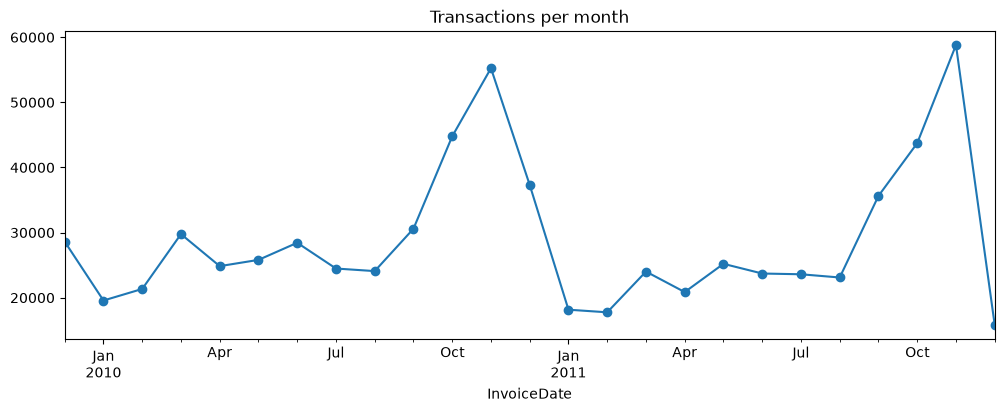

In [10]:
df.groupby(df['InvoiceDate'].dt.to_period('M')).size().plot(kind='line', marker='o', figsize=(12,4), title='Transactions per month')
plt.show()

Seasonal spike: it will peak around Sep to Nov

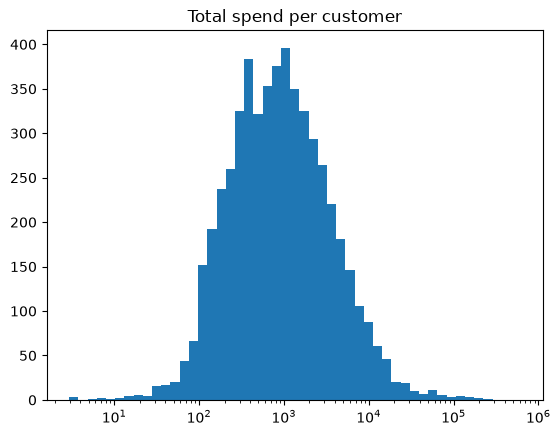

Top 10 frequent buyers:
 CustomerID
12748.0    336
17841.0    211
15311.0    208
13089.0    203
14606.0    192
17850.0    155
18102.0    145
13694.0    143
15061.0    127
14527.0    122
Name: InvoiceNo, dtype: int64
Unique customers: 5350
24.3% of customers drive 80% of revenue


In [11]:
spend = df.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False)
orders = df.groupby('CustomerID')['InvoiceNo'].nunique().sort_values(ascending=False)

plt.hist(spend, bins=np.logspace(np.log10(spend.min()), np.log10(spend.max()), 50))
plt.xscale('log'); plt.title('Total spend per customer'); plt.show()

print('Top 10 frequent buyers:\n', orders.head(10))
print('Unique customers:', df['CustomerID'].nunique())

cum = spend.cumsum() / spend.sum()
pct = ((cum <= 0.8).sum() + 1) / len(spend) * 100
print(f'{pct:.1f}% of customers drive 80% of revenue')

In [12]:
ref_date = pd.Timestamp('2011-12-31')
rfm_df = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (ref_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()
print(rfm_df)
rfm_df.describe()

      CustomerID  Recency  Frequency  Monetary
0        12346.0      346         12  77556.46
1        12608.0      425          1    415.79
2        12745.0      507          2    723.85
3        12746.0      561          1    254.55
4        12747.0       23         26   9276.54
...          ...      ...        ...       ...
5345     18283.0       24         22   2736.65
5346     18284.0      452          1    461.68
5347     18285.0      681          1    427.00
5348     18286.0      497          2   1296.43
5349     18287.0       63          7   4182.99

[5350 rows x 4 columns]


,CustomerID,Recency,Frequency,Monetary
count,5350.000000,5350.000000,5350.000000,5350.000000
mean,15557.362617,223.546168,6.269346,2751.990190
std,1581.161762,209.973818,11.995550,12080.466564
min,12346.000000,21.000000,1.000000,2.950000
25%,14191.250000,46.000000,1.000000,336.167500
50%,15565.500000,119.000000,3.000000,849.910000
75%,16922.750000,402.000000,7.000000,2214.905000
max,18287.000000,759.000000,336.000000,608821.650000


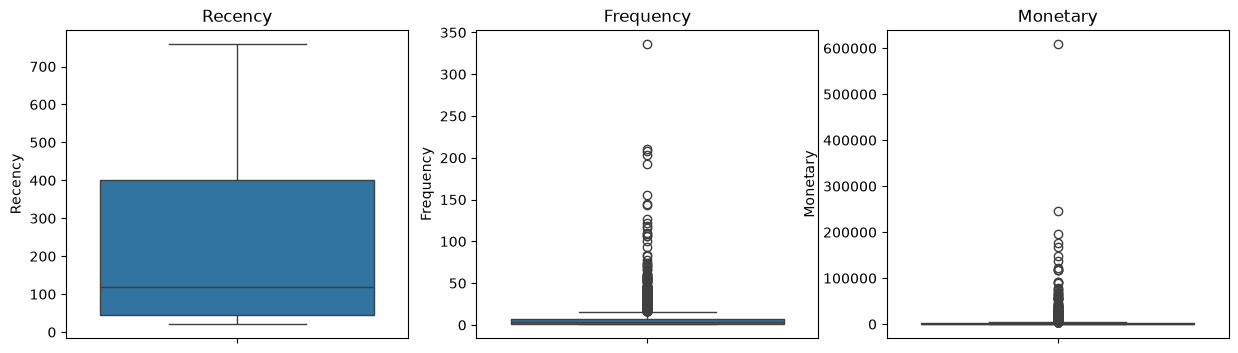

In [13]:
cols = ['Recency','Frequency','Monetary']
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, cols): sns.boxplot(y=rfm_df[c], ax=a); a.set_title(c)
plt.show()

In [14]:
for c in cols:
    q1, q3 = rfm_df[c].quantile([0.25, 0.75])
    rfm_df[c] = rfm_df[c].clip(upper=q3 + 3*(q3 - q1))

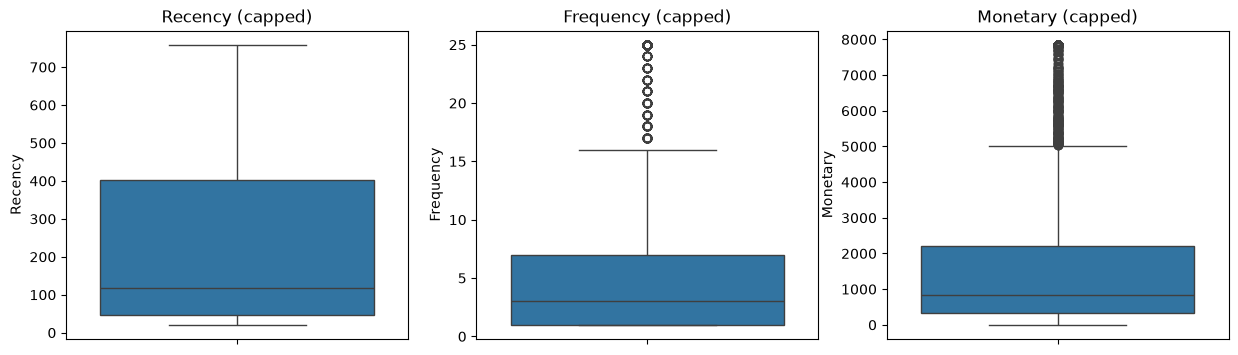

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, cols): sns.boxplot(y=rfm_df[c], ax=a); a.set_title(c + ' (capped)')
plt.show()

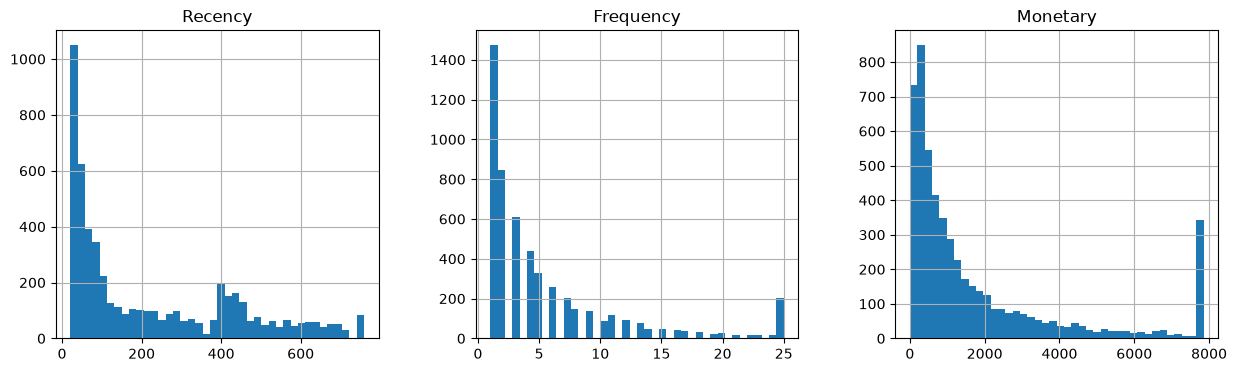

In [16]:
rfm_df[cols].hist(bins=40, figsize=(15,4), layout=(1,3))
plt.show()

In [17]:
rfm_df['Frequency_log'] = np.log1p(rfm_df['Frequency'])
rfm_df['Monetary_log'] = np.log1p(rfm_df['Monetary'])

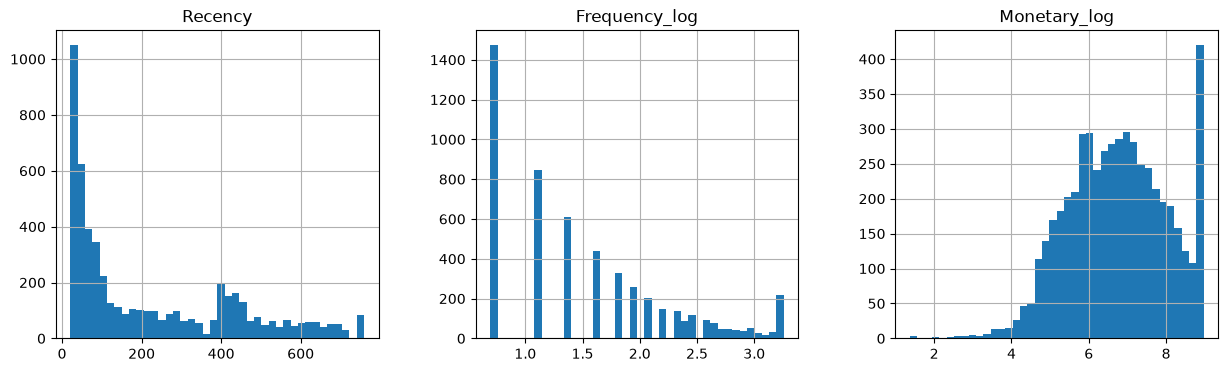

In [18]:
rfm_df[['Recency','Frequency_log','Monetary_log']].hist(bins=40, figsize=(15,4), layout=(1,3))
plt.show()

In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_df[['Recency','Frequency_log','Monetary_log']])
print(rfm_scaled.mean(axis=0).round(3), rfm_scaled.std(axis=0).round(3))

[-0.  0.  0.] [1. 1. 1.]


In [20]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(rfm_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(rfm_scaled, km.labels_))
    print(k, round(km.inertia_, 1), round(sils[-1], 4))

2 7644.7 0.4331
3 4903.9 0.4095
4 3773.8 0.3735
5 2969.2 0.3838
6 2562.2 0.354
7 2258.1 0.3457
8 2056.3 0.346
9 1874.8 0.3213
10 1748.6 0.317


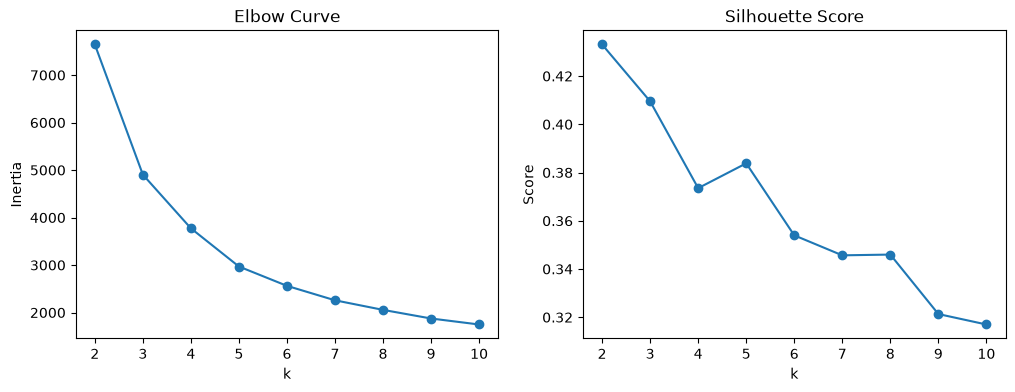

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(ks, inertias, marker='o'); ax[0].set_title('Elbow Curve'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[1].plot(ks, sils, marker='o'); ax[1].set_title('Silhouette Score'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Score')
plt.show()

The silhouette score is highest at k=2 (0.433), but two clusters only separate active from inactive customers, which is too coarse for targeted marketing. The elbow curve bends clearly around k=3 to 4, after which the drop in inertia flattens. I chose k=4 because it sits at the elbow, keeps a reasonable silhouette score (~0.37), and gives enough segments to create meaningful business personas.

In [22]:
km_final = KMeans(n_clusters=4, init='k-means++', n_init=20, max_iter=500, random_state=42).fit(rfm_scaled)
rfm_df['KMeans_Cluster'] = km_final.labels_
rfm_df['KMeans_Cluster'].value_counts()

KMeans_Cluster
3    1684
2    1419
1    1138
0    1109
Name: count, dtype: int64

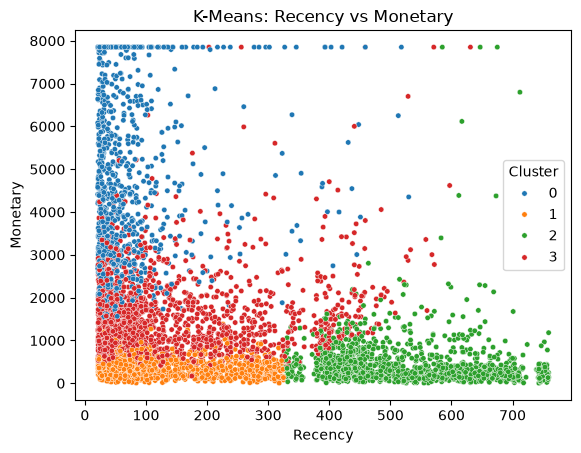

In [23]:
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='KMeans_Cluster', palette='tab10', s=15)
plt.title('K-Means: Recency vs Monetary'); plt.legend(title='Cluster'); plt.show()

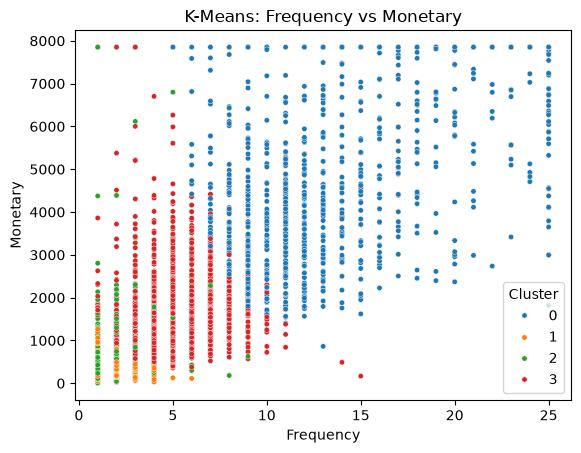

In [24]:
sns.scatterplot(data=rfm_df, x='Frequency', y='Monetary', hue='KMeans_Cluster', palette='tab10', s=15)
plt.title('K-Means: Frequency vs Monetary'); plt.legend(title='Cluster'); plt.show()

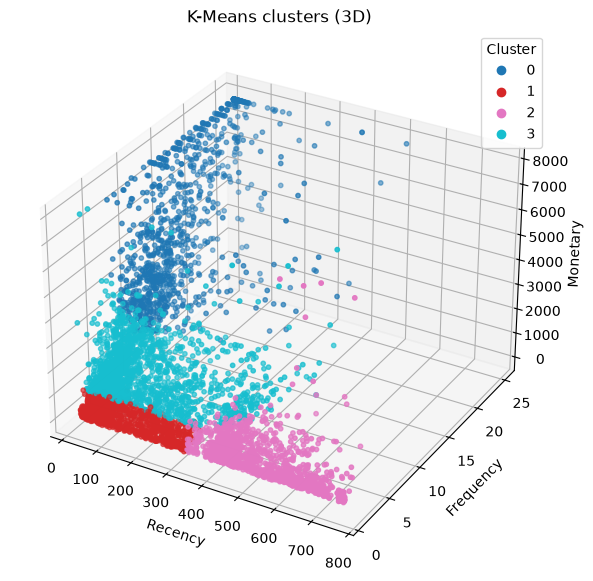

In [25]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(rfm_df['Recency'], rfm_df['Frequency'], rfm_df['Monetary'],
                c=rfm_df['KMeans_Cluster'], cmap='tab10', s=10)
ax.set_xlabel('Recency'); ax.set_ylabel('Frequency'); ax.set_zlabel('Monetary')
ax.set_title('K-Means clusters (3D)')
ax.legend(*sc.legend_elements(), title='Cluster')
plt.show()

In [26]:
profile = rfm_df.groupby('KMeans_Cluster')[['Recency','Frequency','Monetary']].mean().round(1)
profile['Customers'] = rfm_df['KMeans_Cluster'].value_counts()
profile.sort_values('Monetary', ascending=False)

,Recency,Frequency,Monetary,Customers
KMeans_Cluster,,,,
0,65.1,15.1,5232.6,1109
3,139.8,4.8,1551.4,1684
2,521.0,1.6,455.2,1419
1,130.9,1.6,362.9,1138


Cluster 0, Champions: bought recently (~65 days), order very often (~15 orders) and spend the most (~£5,233). These are the VIPs.
Cluster 3, Loyal Customers: reasonably recent (~140 days), repeat buyers (~5 orders) with solid spend (~£1,551). They are good customers who could be moved up to Champions.
Cluster 1, New Customers: fairly recent (~131 days) but only ~1.6 orders and low spend (~£363). They have bought once or twice and are still unproven.
Cluster 2, Hibernating: have not bought in ~521 days, with low frequency and low spend. They are essentially lapsed customers.

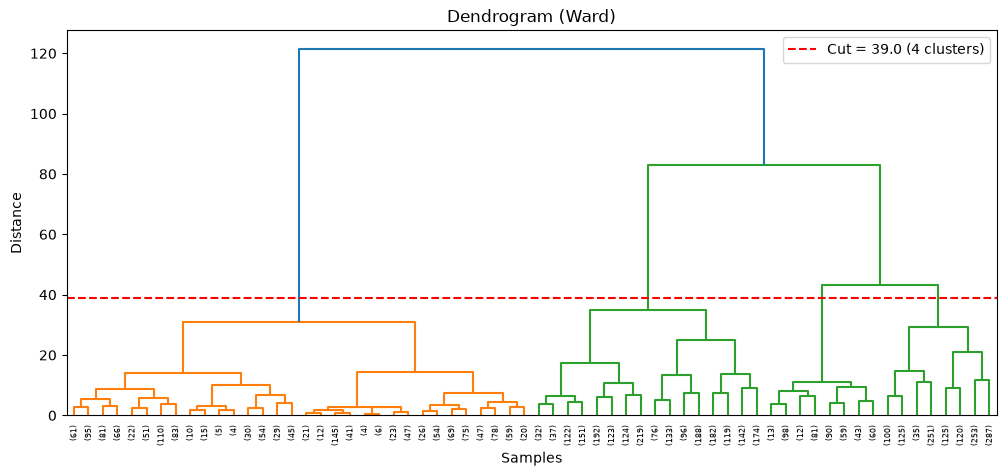

Cut distance for 4 clusters: 39.04


In [27]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(rfm_scaled, method='ward')
cut = (Z[-4, 2] + Z[-3, 2]) / 2   # distance that gives 4 clusters

plt.figure(figsize=(12,5))
dendrogram(Z, truncate_mode='level', p=5)
plt.axhline(y=cut, color='r', linestyle='--', label=f'Cut = {cut:.1f} (4 clusters)')
plt.title('Dendrogram (Ward)'); plt.xlabel('Samples'); plt.ylabel('Distance'); plt.legend()
plt.show()
print('Cut distance for 4 clusters:', round(cut, 2))

Cutting the dendrogram at a distance of about 39 gives 4 clusters, which matches the K-Means choice of k=4. Cutting higher (around 3 clusters) merges distinct customer groups, and cutting lower (5 clusters) splits them into smaller pieces without a clear business meaning.

In [28]:
from sklearn.cluster import AgglomerativeClustering

results = {}
for link in ['ward', 'complete', 'average']:
    labels = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(rfm_scaled)
    results[link] = (silhouette_score(rfm_scaled, labels), labels)
    print(link, round(results[link][0], 4), np.bincount(labels))

ward 0.3708 [2110 1488 1296  456]
complete 0.3075 [3514   41 1178  617]
average 0.3639 [1121 1534 2688    7]


Ward linkage gave the best silhouette score (0.371), followed by average (0.364) and complete (0.308). Ward produced compact, reasonably balanced clusters, similar to K-Means. Complete linkage produced very unequal clusters (one with only 41 customers), and average linkage isolated a tiny cluster of 7 customers, which is not useful for targeting. I selected Ward.

In [29]:
rfm_df['Agg_Cluster'] = results['ward'][1]

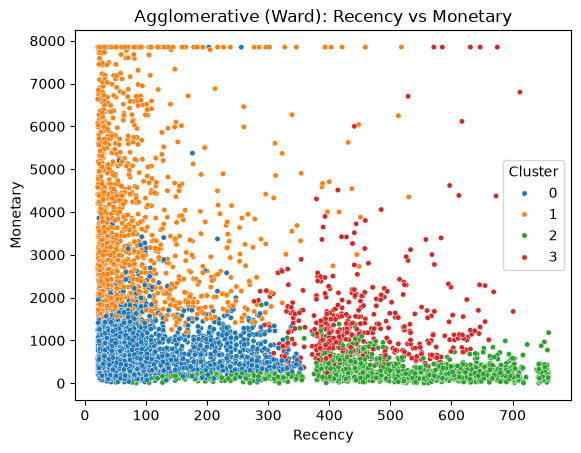

In [30]:
sns.scatterplot(data=rfm_df, x='Recency', y='Monetary', hue='Agg_Cluster', palette='tab10', s=15)
plt.title('Agglomerative (Ward): Recency vs Monetary'); plt.legend(title='Cluster'); plt.show()

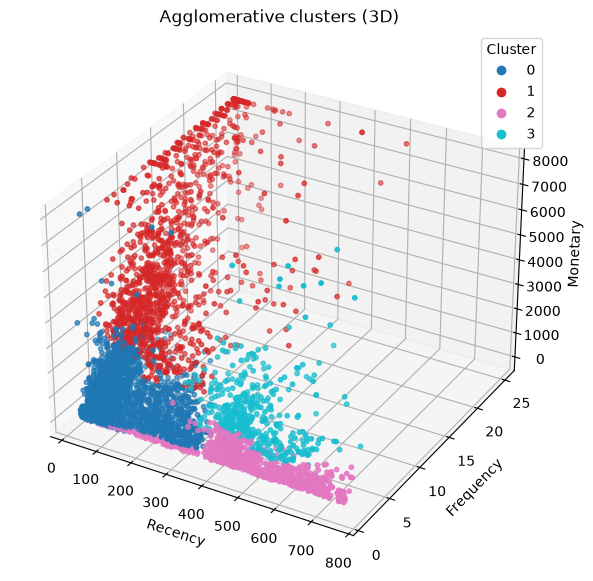

In [31]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(rfm_df['Recency'], rfm_df['Frequency'], rfm_df['Monetary'],
                c=rfm_df['Agg_Cluster'], cmap='tab10', s=10)
ax.set_xlabel('Recency'); ax.set_ylabel('Frequency'); ax.set_zlabel('Monetary')
ax.set_title('Agglomerative clusters (3D)')
ax.legend(*sc.legend_elements(), title='Cluster')
plt.show()

In [32]:
agg_profile = rfm_df.groupby('Agg_Cluster')[['Recency','Frequency','Monetary']].mean().round(1)
agg_profile['Customers'] = rfm_df['Agg_Cluster'].value_counts()
agg_profile.sort_values('Monetary', ascending=False)

,Recency,Frequency,Monetary,Customers
Agg_Cluster,,,,
1,77.8,12.9,4498.8,1488
3,454.9,4.0,1455.8,456
0,109.3,3.0,824.2,2110
2,495.4,1.2,291.2,1296


Cluster 1, Champions: very recent (~78 days), frequent (~13 orders) and highest spend (~£4,499).
Cluster 0, Promising Customers: fairly recent (~109 days), a few orders (~3) and moderate spend (~£824). They can be grown into loyal buyers.
Cluster 3, At-Risk Customers: they used to buy repeatedly (~4 orders, ~£1,456) but have not purchased for ~455 days. They are valuable customers we are close to losing.
Cluster 2, Hibernating: not seen for ~495 days, about one order and the lowest spend (~£291). They are essentially lapsed.

In [33]:
pd.crosstab(rfm_df['KMeans_Cluster'], rfm_df['Agg_Cluster'])

Agg_Cluster,0,1,2,3
KMeans_Cluster,,,,
0,1,1108,0,0
1,984,0,154,0
2,33,0,1141,245
3,1092,380,1,211


The two methods agree strongly on the top segment: 1,108 of the 1,109 K-Means Champions land in the Agg Champions cluster. They disagree on the rest. Hierarchical clustering splits K-Means’ “Hibernating” group into true Hibernating customers and a separate At-Risk group (245 customers with higher past spend). It also divides K-Means’ “Loyal” cluster, sending 380 of its high-value customers up into Champions and most of the rest into the Promising cluster. Ward linkage, like K-Means, produced compact, reasonably balanced clusters.

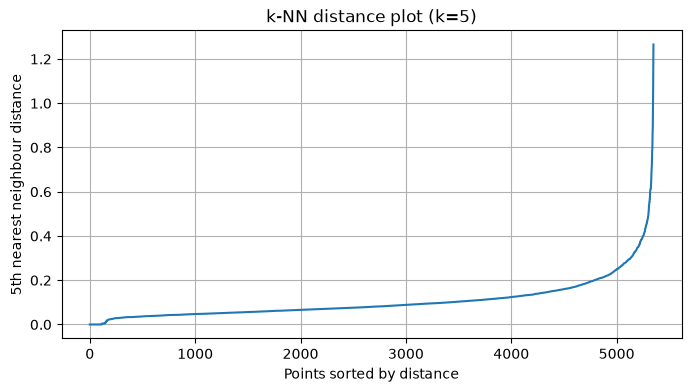

90 percentile: 0.204
95 percentile: 0.279
98 percentile: 0.39
99 percentile: 0.478


In [34]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=5).fit(rfm_scaled)
distances, _ = nn.kneighbors(rfm_scaled)
kdist = np.sort(distances[:, 4])

plt.figure(figsize=(8,4))
plt.plot(kdist)
plt.title('k-NN distance plot (k=5)'); plt.xlabel('Points sorted by distance'); plt.ylabel('5th nearest neighbour distance')
plt.grid(True); plt.show()

for p in [90, 95, 98, 99]:
    print(p, 'percentile:', round(np.percentile(kdist, p), 3))

The k-NN distance curve stays flat for about 95% of customers (distance below ~0.28) and then rises steeply. I chose ε = 0.3 at the start of this rise, so dense customer regions form clusters and the isolated customers on the steep part are labelled as noise.

In [35]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.3, min_samples=5, metric='euclidean').fit(rfm_scaled)
rfm_df['DBSCAN_Cluster'] = db.labels_

n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = (db.labels_ == -1).sum()
print('Clusters (excluding noise):', n_clusters)
print('Noise points:', n_noise)
print('Noise %:', round(n_noise / len(rfm_df) * 100, 2))
print(rfm_df['DBSCAN_Cluster'].value_counts())

Clusters (excluding noise): 5
Noise points: 130
Noise %: 2.43
DBSCAN_Cluster
 2    2934
 0    1446
 1     830
-1     130
 3       6
 4       4
Name: count, dtype: int64


In [36]:
rows = []
for e in [0.3, 0.5, 0.7, 1.0, 1.5]:
    for m in [3, 5, 8, 10]:
        lab = DBSCAN(eps=e, min_samples=m).fit_predict(rfm_scaled)
        mask = lab != -1
        n = len(set(lab[mask]))
        sil = silhouette_score(rfm_scaled[mask], lab[mask]) if n >= 2 else np.nan
        rows.append((e, m, n, round((~mask).mean() * 100, 2), sil))

grid = pd.DataFrame(rows, columns=['eps', 'min_samples', 'clusters', 'noise_pct', 'silhouette'])
grid

,eps,min_samples,clusters,noise_pct,silhouette
0,0.3,3,7,1.61,0.005152
1,0.3,5,5,2.43,0.105491
2,0.3,8,3,3.63,0.198689
3,0.3,10,3,4.41,0.201054
4,0.5,3,3,0.32,0.304084
5,0.5,5,2,0.49,0.333463
6,0.5,8,2,0.73,0.333440
7,0.5,10,2,0.77,0.333265
8,0.7,3,1,0.07,NaN
9,0.7,5,1,0.11,NaN


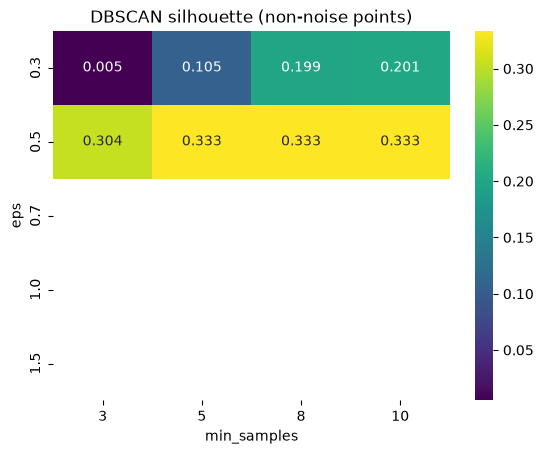

In [37]:
pivot = grid.pivot(index='eps', columns='min_samples', values='silhouette')
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
plt.title('DBSCAN silhouette (non-noise points)'); plt.show()

In [38]:
db = DBSCAN(eps=0.3, min_samples=10).fit(rfm_scaled)
rfm_df['DBSCAN_Cluster'] = db.labels_
print(rfm_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 2    2876
 0    1420
 1     818
-1     236
Name: count, dtype: int64


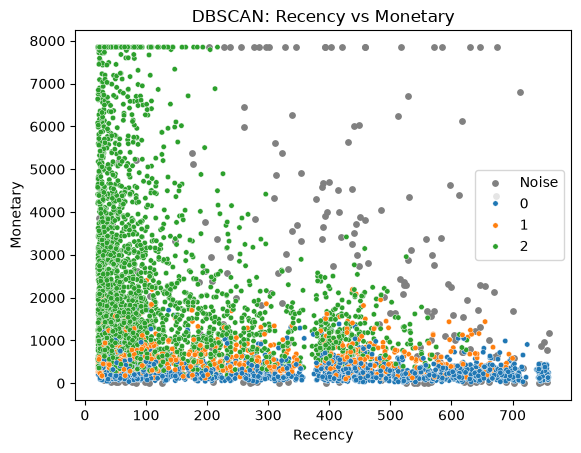

In [39]:
noise = rfm_df[rfm_df['DBSCAN_Cluster'] == -1]
clus = rfm_df[rfm_df['DBSCAN_Cluster'] != -1]
plt.scatter(noise['Recency'], noise['Monetary'], c='grey', s=15, label='Noise')
sns.scatterplot(data=clus, x='Recency', y='Monetary', hue='DBSCAN_Cluster', palette='tab10', s=15)
plt.title('DBSCAN: Recency vs Monetary'); plt.legend(); plt.show()

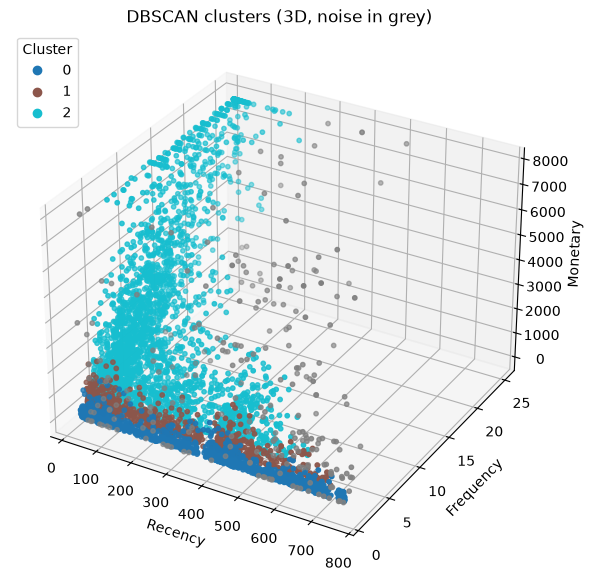

In [40]:
fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noise['Recency'], noise['Frequency'], noise['Monetary'], c='grey', s=10, label='Noise')
sc = ax.scatter(clus['Recency'], clus['Frequency'], clus['Monetary'], c=clus['DBSCAN_Cluster'], cmap='tab10', s=10)
ax.set_xlabel('Recency'); ax.set_ylabel('Frequency'); ax.set_zlabel('Monetary')
ax.set_title('DBSCAN clusters (3D, noise in grey)')
ax.legend(*sc.legend_elements(), title='Cluster', loc='upper left')
plt.show()

In [41]:
db_profile = clus.groupby('DBSCAN_Cluster')[['Recency','Frequency','Monetary']].mean().round(1)
db_profile['Customers'] = clus['DBSCAN_Cluster'].value_counts()
print(db_profile)
print('\nNoise customers (average):')
print(noise[['Recency','Frequency','Monetary']].mean().round(1))

                Recency  Frequency  Monetary  Customers
DBSCAN_Cluster                                         
0                 378.0        1.0     287.0       1420
1                 261.8        2.0     590.4        818
2                 121.0        8.5    2784.5       2876

Noise customers (average):
Recency       411.6
Frequency       5.8
Monetary     2440.1
dtype: float64


In [42]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

def scores(X, lab):
    return (len(set(lab)),
            round(silhouette_score(X, lab), 4),
            round(davies_bouldin_score(X, lab), 4),
            round(calinski_harabasz_score(X, lab), 1))

mask = db.labels_ != -1
comp = pd.DataFrame(
    [('K-Means', 'k=4, n_init=20', *scores(rfm_scaled, rfm_df['KMeans_Cluster'].values), 0.0),
     ('Agglomerative', 'ward, n_clusters=4', *scores(rfm_scaled, rfm_df['Agg_Cluster'].values), 0.0),
     ('DBSCAN', 'eps=0.3, min_samples=10', *scores(rfm_scaled[mask], db.labels_[mask]), round((~mask).mean()*100, 2))],
    columns=['Algorithm', 'Hyperparameters', 'Clusters', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Noise %'])
comp

,Algorithm,Hyperparameters,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise %
0,K-Means,"k=4, n_init=20",4,0.3735,0.9054,5797.0,0.00
1,Agglomerative,"ward, n_clusters=4",4,0.3708,0.8786,4867.1,0.00
2,DBSCAN,"eps=0.3, min_samples=10",3,0.2011,1.7719,2809.4,4.41


Ranking (best to worst): 1) K-Means, 2) Agglomerative (Ward), 3) DBSCAN.
K-Means has the highest Silhouette (0.3735), the lowest Davies-Bouldin (0.9054, lower is better) and the highest Calinski-Harabasz (5797). Agglomerative is very close behind on all three. DBSCAN is clearly worst: Silhouette 0.2011, Davies-Bouldin 1.7719, Calinski-Harabasz 2809. Its metrics are also computed only on non-noise points (4.41% of customers were excluded), so they are slightly flattered. K-Means therefore produced the most well-separated, compact clusters.

In [43]:
stab = []
for seed in [0, 7, 21, 42, 99]:
    lab = KMeans(n_clusters=4, init='k-means++', n_init=20, max_iter=500, random_state=seed).fit_predict(rfm_scaled)
    stab.append(silhouette_score(rfm_scaled, lab))
    print(seed, round(stab[-1], 4))
print('Mean ± std:', round(np.mean(stab), 4), '±', round(np.std(stab), 4))

0 0.3735
7 0.3735
21 0.3735
42 0.3735
99 0.3735
Mean ± std: 0.3735 ± 0.0


Silhouette scores across the 5 random seeds (0, 7, 21, 42, 99) were identical: mean 0.3735 ± 0.0. K-Means is fully stable on this data. The clusters are well defined, and with n_init=20 the algorithm converges to the same solution every time.

In [44]:
rfm_df['KMeans_Cluster'].value_counts(normalize=True).mul(100).round(1)

KMeans_Cluster
3    31.5
2    26.5
1    21.3
0    20.7
Name: proportion, dtype: float64

Recommended algorithm: K-Means (k=4). It scored best on all three metrics, gave the same result on every random seed, and can easily assign new customers to a segment.

Segments and actions:

Champions: recent, frequent, highest spend. Action: invite to an exclusive loyalty programme.
Loyal Customers: repeat buyers with solid spend. Action: send personalised offers to move them up to Champions.
New Customers: bought once or twice, low spend. Action: send a welcome offer for a second purchase.
Hibernating: inactive for over a year, low spend. Action: send a win-back coupon with a 7-day expiry.

Extra data that would help: product categories, returns, discount usage, and email click rates.

In [45]:
import joblib
persona_map = {0: 'Champions', 3: 'Loyal Customers', 1: 'New Customers', 2: 'Hibernating'}
joblib.dump(scaler, 'rfm_scaler.pkl')
joblib.dump(km_final, 'customer_segmentation_model.pkl')

['customer_segmentation_model.pkl']

In [46]:
def predict_segment(recency, frequency, monetary):
    x = pd.DataFrame([[recency, np.log1p(frequency), np.log1p(monetary)]],
                     columns=['Recency', 'Frequency_log', 'Monetary_log'])
    label = int(km_final.predict(scaler.transform(x))[0])
    return label, persona_map[label]

In [47]:
tests = [(10, 20, 8000), (150, 5, 1500), (120, 1, 300), (600, 1, 400), (30, 2, 500)]
for r, f, m in tests:
    print(f'R={r}, F={f}, M={m} ->', predict_segment(r, f, m))

R=10, F=20, M=8000 -> (0, 'Champions')
R=150, F=5, M=1500 -> (3, 'Loyal Customers')
R=120, F=1, M=300 -> (1, 'New Customers')
R=600, F=1, M=400 -> (2, 'Hibernating')
R=30, F=2, M=500 -> (1, 'New Customers')


The predict_segment() function applies the same log1p transform and scaling used in training, then assigns the nearest K-Means cluster. Tested on 5 hypothetical customers, each was placed in a persona matching its RFM profile.